# Hands-On Activity 05: TCGA Breast Cancer Mutation Frequencies
Nicholas Hoang

I used the TCGA BRCA MC3 gene-level dataset from UCSC Xena. I define mutation frequency as the number of tumor samples with at least one non-silent mutation in a gene. Each sample counts once per gene, even if it has multiple mutations in that gene.


In [1]:
from pathlib import Path

import pandas as pd
from google.colab import files

data_path = Path("data/BRCA_mc3_gene_level.txt")
data_path.parent.mkdir(exist_ok=True)

if not data_path.exists():
    uploaded = files.upload()
    data_path.write_bytes(uploaded[data_path.name])

mutations = pd.read_csv(data_path, sep="\t", index_col=0)

# Each row is a gene. Each column is a tumor sample.
# A value of 1 means the sample has a non-silent mutation in that gene.
mutation_frequency = mutations.eq(1).sum(axis=1)
top_25 = mutation_frequency.nlargest(25)

print(f"Tumor samples analyzed: {mutations.shape[1]}")
display(top_25.to_frame("Samples with at least one mutation"))

Saving BRCA_mc3_gene_level.txt to BRCA_mc3_gene_level.txt
Tumor samples analyzed: 791


,Samples with at least one mutation
sample,
PIK3CA,273
TP53,264
TTN,137
CDH1,102
GATA3,97
MUC16,78
KMT2C,77
MAP3K1,66
SYNE1,50


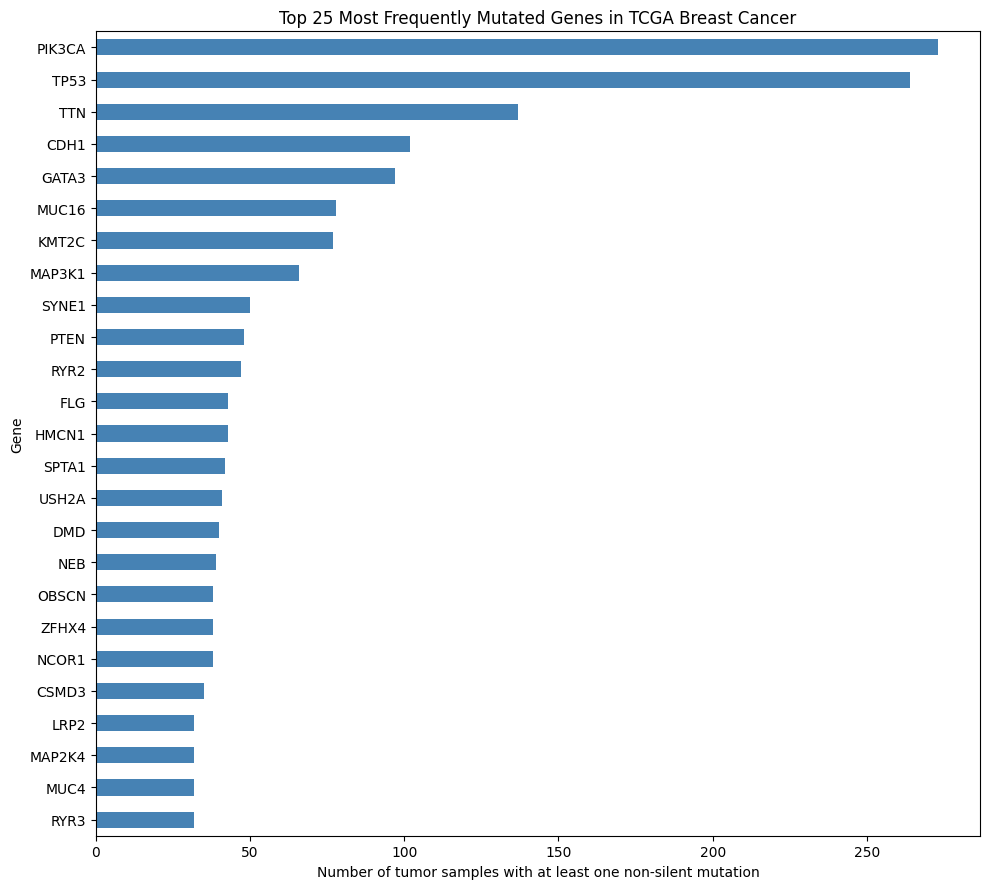

In [2]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 9))
top_25.iloc[::-1].plot.barh(ax=ax, color="steelblue")

ax.set_title("Top 25 Most Frequently Mutated Genes in TCGA Breast Cancer")
ax.set_xlabel("Number of tumor samples with at least one non-silent mutation")
ax.set_ylabel("Gene")

fig.tight_layout()
fig.savefig("activity_05_top_25.png", dpi=200, bbox_inches="tight")
plt.show()

## Interpretation

PIK3CA was the most frequently mutated gene, with mutations in 273 of 791 tumor samples, followed by TP53 in 264 samples. TTN, CDH1, and GATA3 rounded out the top five. PIK3CA and TP53 are known breast cancer driver genes, so their high rankings were expected. TTN is a very large gene, which gives it more DNA positions where a mutation could occur by chance. Some of those mutations may be passengers that do not contribute to tumor growth. The raw counts also do not account for differences in sequencing coverage or in how many mutations each tumor carries.

## Reflection

1. **Does high mutation frequency imply functional importance?** No. A high count tells me how often the gene was mutated in this cohort. I would need more evidence to tell whether those mutations helped the tumor grow.
2. **What biases might affect the ranking?** Gene length, sequencing coverage, differences in overall mutation burden, and the mix of breast cancer subtypes can all affect the rankings.
3. **How could I better identify driver genes?** I would compare how often each gene was mutated with how often I would expect it to mutate by chance, accounting for factors such as gene length and sequencing coverage. I would also look for mutations that recur at the same position or repeatedly disrupt the gene's function.